# Spotify Music Clustering and Recommendation System
## 1. Import Libraries

This project uses unsupervised machine learning to group similar Spotify tracks
and recommend songs based on their audio features.

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load Dataset

Load the Spotify dataset and inspect its dimensions and contents.

In [43]:
df = pd.read_csv("data/dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
pd.set_option("display.max_columns",None)
df.head()

Dataset loaded successfully!
Number of rows: 114000
Number of columns: 21


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [44]:
print(df.columns.tolist())
df.info()

['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  


## 3 Missing Values

now lets handle missing values

In [45]:
missing_values = df.isnull().sum()
print(missing_values)
print("Duplicate rows:", df.duplicated().sum())
df.describe()
df.dropna(inplace=True)


Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64
Duplicate rows: 0


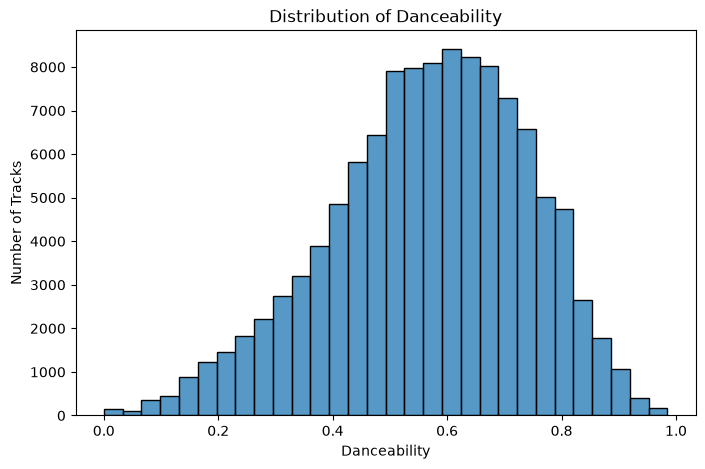

In [46]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="danceability", bins=30)

plt.title("Distribution of Danceability")
plt.xlabel("Danceability")
plt.ylabel("Number of Tracks")

plt.show()

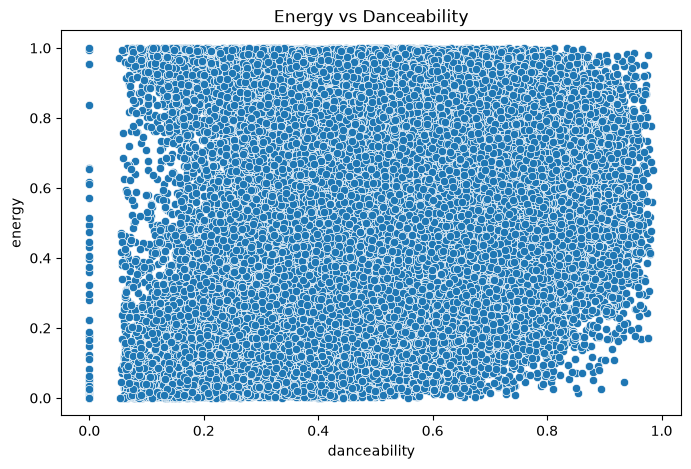

In [47]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="danceability",
    y="energy"
)

plt.title("Energy vs Danceability")
plt.show()

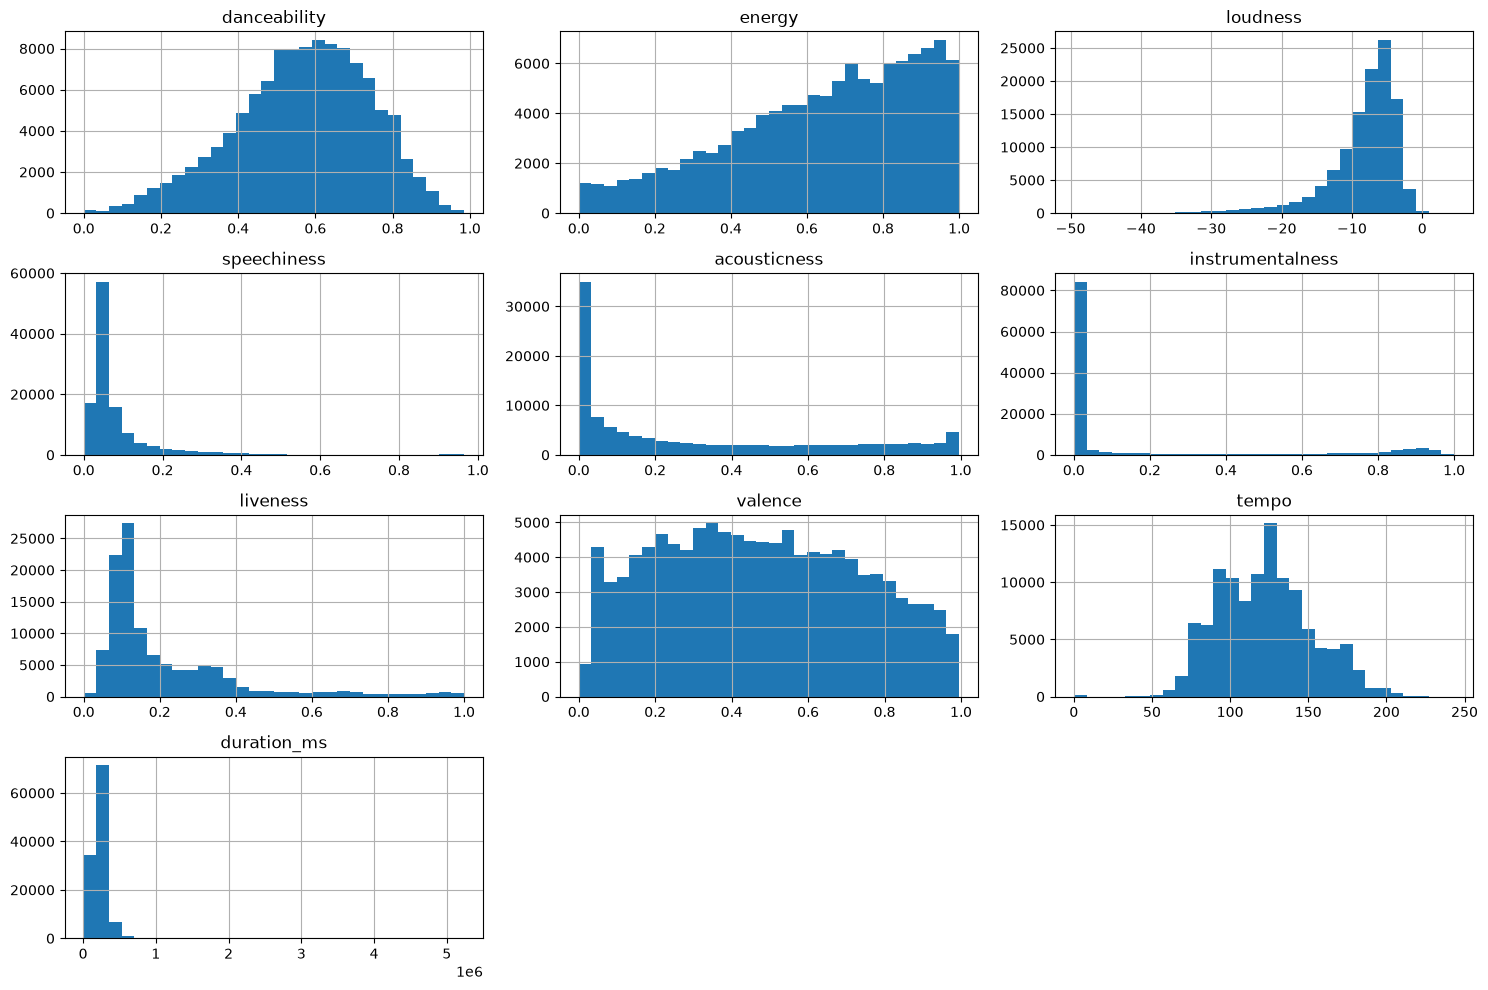

In [48]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms"
]

df[audio_features].hist(figsize=(15, 10), bins=30)

plt.tight_layout()
plt.show()

## 4. Data Preprocessing

In this section, we will:
1. Select numerical audio features.
2. Handle missing values.
3. Remove duplicate feature records.
4. Prepare the data for clustering.

In [49]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms"
]

X = df[audio_features].copy()

print("Selected features:", X.shape[1])
print("Number of tracks:", X.shape[0])

Selected features: 10
Number of tracks: 113999


In [50]:
print("Duplicate feature rows:", X.duplicated().sum())

Duplicate feature rows: 30521


## 5. Feature Scaling

Standardize audio features so that features with larger numerical ranges
do not dominate distance calculations in K-Means.

In [51]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)

Original data shape: (113999, 10)
Scaled data shape: (113999, 10)


## 6. Finding the Optimal Number of Clusters

### 6.1 Elbow Method

We calculate WCSS for different values of K and plot the results
to identify a reasonable number of clusters.

In [52]:
wcss = []

for k in range(2, 11):
    print("Training K-Means with K =", k)
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
print("WCSS values:", wcss)

Training K-Means with K = 2
Training K-Means with K = 3
Training K-Means with K = 4
Training K-Means with K = 5
Training K-Means with K = 6
Training K-Means with K = 7
Training K-Means with K = 8
Training K-Means with K = 9
Training K-Means with K = 10
WCSS values: [919438.4980631763, 825996.2244112968, 756806.3624745989, 693848.872524169, 641706.323962983, 592119.103331075, 564028.1181130294, 536050.7400467031, 510445.0039931432]


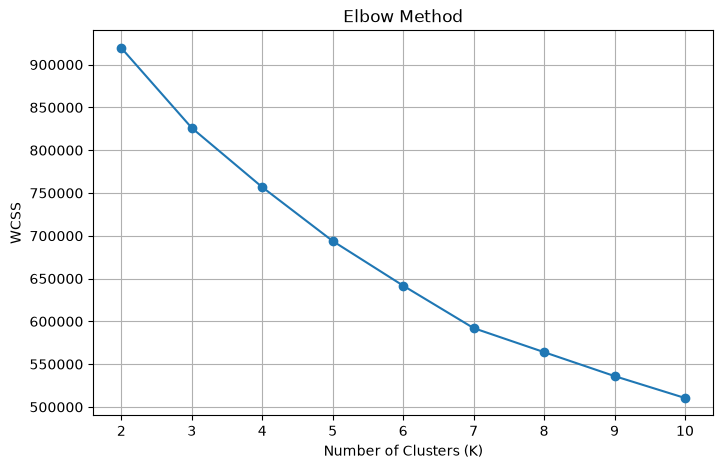

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

### 6.2 Silhouette Score

Compare the clustering quality for different values of K.

In [54]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    print("Calculating silhouette score for K =", k)

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=5000,
        random_state=42
    )

    silhouette_scores.append(score)

    print("Silhouette Score:", round(score, 4))

print("All silhouette scores:", silhouette_scores)

Calculating silhouette score for K = 2
Silhouette Score: 0.2443
Calculating silhouette score for K = 3
Silhouette Score: 0.1633
Calculating silhouette score for K = 4
Silhouette Score: 0.1674
Calculating silhouette score for K = 5
Silhouette Score: 0.1705
Calculating silhouette score for K = 6
Silhouette Score: 0.1733
Calculating silhouette score for K = 7
Silhouette Score: 0.1844
Calculating silhouette score for K = 8
Silhouette Score: 0.1857
Calculating silhouette score for K = 9
Silhouette Score: 0.1857
Calculating silhouette score for K = 10
Silhouette Score: 0.1705
All silhouette scores: [0.24429351723431092, 0.163271373681056, 0.16740026386740287, 0.17052069851966248, 0.17325612534844448, 0.18441315147967724, 0.18573815558040693, 0.18565036739196134, 0.1705304140419115]


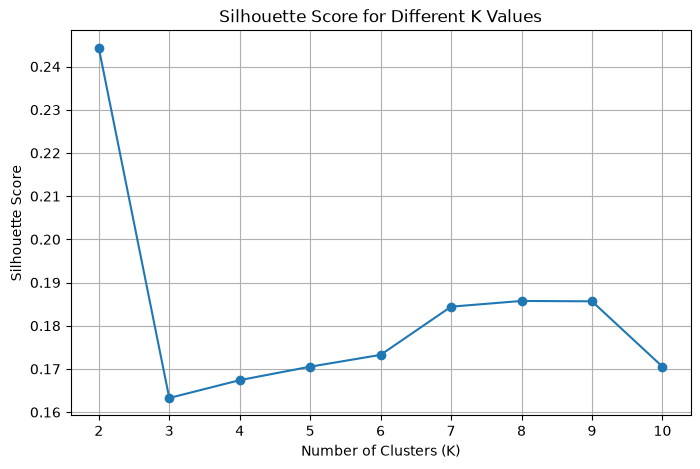

In [55]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

## 7. Train the Final K-Means Model

In [56]:
best_k = 8

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

clusters = kmeans_model.fit_predict(X_scaled)

df["cluster"] = clusters

print("K-Means training completed!")
print("Number of clusters:", best_k)
print("\nTracks in each cluster:")
print(df["cluster"].value_counts().sort_index())

K-Means training completed!
Number of clusters: 8

Tracks in each cluster:
cluster
0     7402
1     6971
2    22294
3     7393
4    25026
5    11264
6      939
7    32710
Name: count, dtype: int64


## 8.PCA

now let's visualize the model using PCA

In [57]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Number of PCA components:", X_pca.shape[1])

print(
    "Explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

Original number of features: 10
Number of PCA components: 2
Explained variance: 0.4398


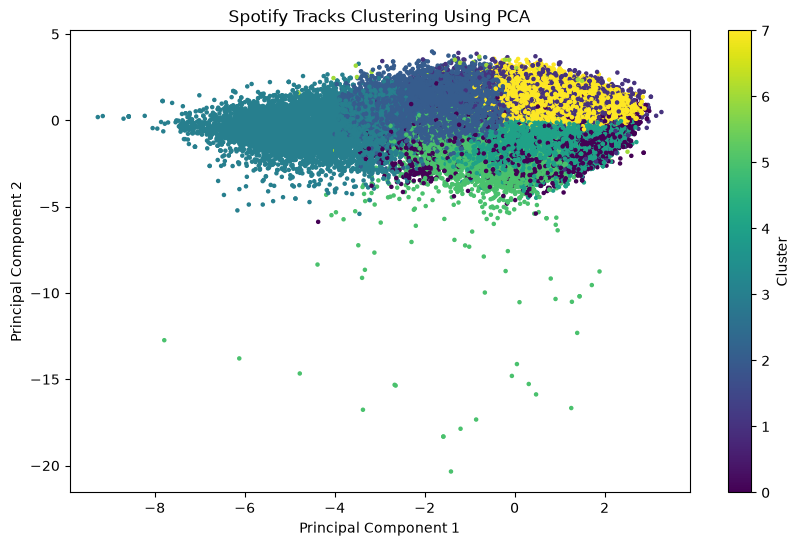

In [58]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=5
)

plt.title("Spotify Tracks Clustering Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(label="Cluster")
plt.show()

## 9 Analyze clusters

now lets analyze the clusters


In [59]:
cluster_counts = df["cluster"].value_counts().sort_index()
print(cluster_counts)

cluster
0     7402
1     6971
2    22294
3     7393
4    25026
5    11264
6      939
7    32710
Name: count, dtype: int64


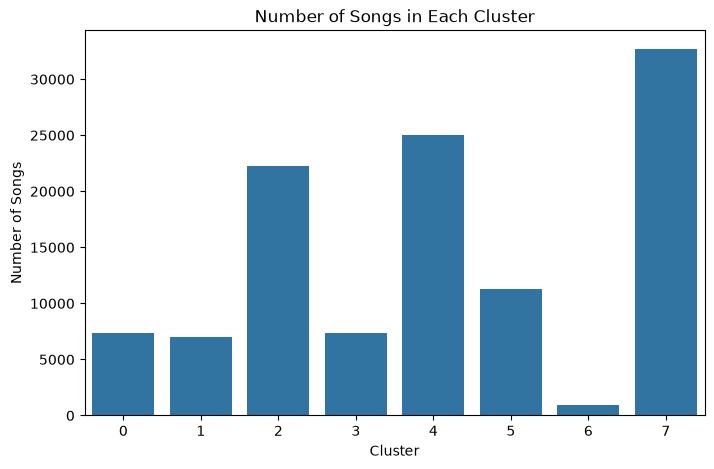

In [60]:
plt.figure(figsize=(8, 5))

sns.barplot(x=cluster_counts.index, y=cluster_counts.values)

plt.title("Number of Songs in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Songs")

plt.show()

In [61]:
cluster_analysis = df.groupby("cluster")[audio_features].mean()

cluster_analysis.round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
cluster,,,,,,,,,,
0,0.52,0.75,-7.03,0.08,0.29,0.07,0.75,0.51,123.42,237994.49
1,0.70,0.67,-7.01,0.31,0.26,0.03,0.18,0.56,124.40,194717.51
2,0.53,0.37,-10.67,0.05,0.69,0.04,0.16,0.39,113.07,214256.75
3,0.35,0.17,-21.17,0.05,0.86,0.79,0.16,0.19,103.21,213776.53
4,0.46,0.81,-5.37,0.07,0.07,0.04,0.19,0.36,139.14,236240.75
5,0.59,0.74,-8.47,0.07,0.10,0.78,0.17,0.33,126.94,311032.14
6,0.56,0.69,-11.32,0.88,0.77,0.01,0.71,0.43,99.84,223227.46
7,0.69,0.73,-6.29,0.06,0.20,0.02,0.17,0.70,117.84,210760.78


## 10. Song Recommendation System

Recommend songs using their audio features and cosine similarity.
First, identify the selected song's cluster, then rank other songs
in that cluster by similarity.

In [62]:
def recommend_songs(song_name, number_of_recommendations=10):

    # Find the song
    matches = df[
        df["track_name"].str.contains(
            song_name,
            case=False,
            na=False
        )
    ]

    if matches.empty:
        print("Song not found!")
        return

    # Select the first matching song
    song_index = matches.index[0]

    # Find the cluster of the selected song
    song_cluster = df.loc[song_index, "cluster"]

    # Get songs from the same cluster
    cluster_indices = df.index[
        df["cluster"] == song_cluster
    ]

    # Find the position of the selected song in X_scaled
    song_position = df.index.get_loc(song_index)

    # Calculate similarity with songs in the same cluster
    similarity_scores = cosine_similarity(
        X_scaled[[song_position]],
        X_scaled[[df.index.get_loc(i) for i in cluster_indices]]
    )[0]

    # Store song indices and similarity scores
    recommendations = pd.DataFrame({
        "index": cluster_indices,
        "similarity": similarity_scores
    })

    # Remove the selected song
    recommendations = recommendations[
        recommendations["index"] != song_index
    ]

    # Sort by similarity
    recommendations = recommendations.sort_values(
        by="similarity",
        ascending=False
    )

    # Select the top recommendations
    recommendations = recommendations.head(
        number_of_recommendations
    )

    # Display song information
    result = df.loc[
        recommendations["index"],
        ["track_name", "artists", "track_genre"]
    ].copy()

    result["similarity"] = recommendations["similarity"].values

    return result.reset_index(drop=True)
recommend_songs("Blinding Lights", 10)

,track_name,artists,track_genre,similarity
0,Atrakce,PAWLIE POIZN;Medooza,emo,0.989448
1,My Person,Spencer Crandall,country,0.986191
2,My Person,Spencer Crandall,country,0.985536
3,Mob Rule,Bad//Dreems,garage,0.985454
4,Me Voy,Los Victorios,ska,0.984431
5,1+1,Ready Kirken,folk,0.979122
6,Rock de la Cárcel,Palito Ortega,rock-n-roll,0.977579
7,La Alegría en Serio,Los Caligaris,ska,0.977405
8,The Middle,Jimmy Eat World,alternative,0.975559
9,The Middle,Jimmy Eat World,alternative,0.975559


## 10.now let us save the model,scaler and PCA as pikle file

In [63]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(kmeans_model, "models/kmeans_model.pkl")

joblib.dump(scaler, "models/scaler.pkl")

joblib.dump(
    {
        "data": df,
        "features": audio_features,
        "scaled_features": X_scaled,
        "pca": pca
    },
    "models/recommendation_data.pkl"
)

print("Models and recommendation data saved successfully!")

Models and recommendation data saved successfully!
